In [ ]:
import random
import json
import string
import calendar
import json
import torch
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer
from datasets import Dataset
from transformers import (
    AutoModelForTokenClassification,
    TrainingArguments,
    Trainer,
    DataCollatorForTokenClassification
)

합성 데이터셋 생성

In [ ]:
# import random
# import json
# import string
# import calendar

# 성씨 풀
surnames = [
    "김","이","박","최","정","강","조","윤","장","임","한","오","서","신","권","황",
    "안","송","전","홍","유","고","문","양","손","배","백","허","남","심","노","하",
    "곽","성","차","주","우","구","민","나","진","지","엄","채","원","천","방","공",
    "현","함","변","염","여","추","도","소","석","선","설","마","길","연","위","표",
    "명","기","반","왕","금","옥","육","인","맹","제","모","탁","국","어"
]

# === 복성: 학습용 & 테스트 전용 분리 ===
train_compound = ["남궁", "황보", "제갈"]
test_only_compound = ["독고", "서문", "사공"]

# 이름 풀 (성과 조합해서 이름 합성)
given_names = [
    "민준","서연","도윤","하은","시우","지안","주원","서윤","예준","수아",
    "지호","하윤","준서","지우","건우","나윤","우진","아린","선우","다은",
    "영수","철수","순자","정숙","미영","경자","광수","성민","혜진","지훈"
]

# === 주소: 학습용 25개 + 테스트 전용 5개 분리 ===
train_addresses = [
    "서울특별시 강남구 테헤란로 152",
    "부산광역시 해운대구 센텀중앙로 79",
    "경기도 성남시 분당구 판교역로 235",
    "인천광역시 연수구 컨벤시아대로 165",
    "대구광역시 수성구 동대구로 366",
    "대전광역시 유성구 대학로 291",
    "광주광역시 서구 상무중앙로 61",
    "울산광역시 남구 삼산로 282",
    "경기도 가평군 가평읍 가화로 164",
    "강원도 평창군 대화면 가평로 19-1",
    "제주특별자치도 제주시 첨단로 242",
    "경기도 고양시 덕양구 화중로 164, 512동 1004호",
    "서울특별시 마포구 월드컵북로 396",
    "서울특별시 종로구 사직로 161",
    "경기도 수원시 영통구 광교로 145",
    "경기도 용인시 기흥구 동백중앙로 191",
    "부산광역시 부산진구 서면로 68",
    "대구광역시 중구 동성로2길 81",
    "광주광역시 북구 첨단과기로208번길 43",
    "전라북도 전주시 완산구 홍산로 276",
    "전라남도 여수시 웅천남로 30",
    "충청북도 청주시 흥덕구 오송읍 오송생명2로 187",
    "충청남도 천안시 서북구 불당대로 234",
    "강원도 춘천시 삭주로 3",
    "경상북도 포항시 남구 지곡로 80",
]
test_only_addresses = [
    "경상남도 창원시 성산구 창이대로 689",
    "세종특별자치시 한누리대로 2130",
    "제주특별자치도 서귀포시 중문관광로 72",
    "인천광역시 미추홀구 인주대로 526",
    "울산광역시 중구 성남동 355-1",
]

# 메일 도메인
domains = ["naver.com", "gmail.com", "daum.net", "kakao.com", "nate.com", "hanmail.net"]

# 8% 미만의 확률로 train_compound 중에서 성을 뽑고, 92%는 일반 성에서 뽑는다.
def gen_name(pool="train"):
    if pool == "test_only":
        surname = random.choice(test_only_compound)
    else:
        if random.random() < 0.08:
            surname = random.choice(train_compound)
        else:
            surname = random.choice(surnames)
    # 마지막으로 성+이름 조합
    return surname + random.choice(given_names)

# 테스트 주소를 하나 선택하여 반환
def gen_addr(pool="train"):
    if pool == "test_only":
        return random.choice(test_only_addresses)
    return random.choice(train_addresses)

# 핸드폰 번호 생성
def gen_phone():
    # 85% 확률로 010로 시작하는 번호를 만듬. 중간자리(mid)는 0000~9999사이 랜덤 값을 선택
    if random.random() < 0.85:
        prefix = "010"
        mid = f"{random.randint(0,9999):04d}"
    # 나머지 15% 확률로는 옛날 번호, 중간자리도 3자리
    else:
        prefix = random.choice(["011","016","017","018","019"])
        mid = f"{random.randint(0,999):03d}" if random.random() < 0.5 else f"{random.randint(0,9999):04d}"

    # 마지막 자리(last)는 4자리
    last = f"{random.randint(0,9999):04d}"

    # dash(-), none, space(띄어쓰기), dot(.) 으로 자릿수 사이에 어떤 구분 기호를 쓸지 분류. 40, 15, 25, 20의 가중치
    style = random.choices(["dash", "none", "space", "dot"], weights=[40, 15, 25, 20])[0]
    # 각 스타일에 맞게 전화번호 표현
    if style == "none":
        return f"{prefix}{mid}{last}"
    elif style == "space":
        return f"{prefix} {mid} {last}"
    elif style == "dot":
        return f"{prefix}.{mid}.{last}"
    else:
        return f"{prefix}-{mid}-{last}"

# 5~10자리 랜덤 문자열을 생성후, 위의 domain 풀에서 하나 선택 및 조합하여 이메일 생성
def gen_email():
    id_str = ''.join(random.choices(string.ascii_lowercase + string.digits, k=random.randint(5,10)))
    return f"{id_str}@{random.choice(domains)}"

# 주민등록 번호 생성
def gen_rrn():
    year = random.randint(1950, 2023)
    month = random.randint(1, 12)
    day = random.randint(1, calendar.monthrange(year, month)[1])
    yy = f"{year % 100:02d}"
    gender_digit = random.choice("12345678")
    rest = f"{random.randint(0, 999999):06d}"
    front = f"{yy}{month:02d}{day:02d}"
    back = f"{gender_digit}{rest}"

    # 스타일 (-, 이어붙임, 띄어쓰기)로 표현. 가중치 50, 30, 20
    style = random.choices(["dash", "none", "space"], weights=[50, 30, 20])[0]
    if style == "none":
        return f"{front}{back}"
    elif style == "space":
        return f"{front} {back}"
    else:
        return f"{front}-{back}"

# 전화번호/주민번호 문자열을 받아서 그 안에 어떤 구분 기호가 들어있는지 보고 역으로 스타일명을 판정
def format_style(value):
    if "-" in value:
        return "dash"
    elif " " in value:
        return "space"
    elif "." in value:
        return "dot"
    else:
        return "none"

# 실제 업무 상황에서 개인정보가 언급될만한 문장 풀
TEMPLATES = [
    "{name}님의 연락처는 {phone}입니다.",
    "제 이메일은 {email}이고, 전화번호는 {phone}이에요.",
    "{name} 고객님, 주민등록번호 {rrn} 확인 부탁드립니다.",
    "배송지 주소는 {addr}로 해주세요.",
    "{name}님 앞으로 등기 하나 왔는데, {addr}로 보내드릴까요?",
    "이름은 {name}이고 이메일은 {email}입니다.",
    "{addr}에 사는 {name}입니다.",
    "주민번호 {rrn}인 {name}님 본인 확인 완료했습니다.",
    "연락 주실 땐 {phone}으로 해주시고, 이메일은 {email}로 보내주세요.",
    "{name} 부장님께 {phone}로 전화 부탁드립니다.",
    "신청서에 적힌 이름 {name}, 주소 {addr} 맞으신가요?",
    "{email}로 인증코드 보내드렸습니다.",
    "택배는 {addr}으로 배송될 예정입니다.",
    "{rrn} 이 번호로 조회하니 {name}님 본인이시네요.",
    "다음 상담자는 {name}님이고, 전화번호는 {phone}입니다.",
]

# 민감정보가 포함되지 않는 일상적인 문장 풀
NEGATIVE_SENTENCES = [
    "오늘 날씨가 정말 좋네요.",
    "회의는 내일 오후 3시에 진행됩니다.",
    "이 프로젝트 마감일이 다음 주까지예요.",
    "점심 메뉴로 뭐 드실래요?",
    "보고서 검토 부탁드립니다.",
    "오후에 회의 예정되어있습니다."
]

TEMPLATES_CASUAL = [
    # 존댓말 신호 없는 이름 언급
    "{name}이가 그러던데 맞나요",
    "{name} 오늘 뭐하냐",
    "{name}한테 한번 물어봐",
    "저기 {name} 있네",
    "{name} 이번에 승진했대",
    # 직함/역할 뒤에 이름 (역순 구조)
    "담당자 이름이 {name}였어요",
    "작성자는 {name}입니다",
    # 070 등 다른 전화 접두사
    "070으로 시작하는 번호예요 {phone}",
]

# 아래 문장들은 전부 정답이 "없는" 문장들임
NEGATIVE_HARD = [
    # 지명스러운 단어지만 정식 주소 아님 (ADDR 오탐 방지용)
    "강남역 3번출구에서 봐요",
    "여의도 본사로 오시면 됩니다",
    "제주도 여행 다녀왔어요",
    "판교역 스타벅스 앞이에요",
    "부산 해운대 쪽이에요",
    # 숫자 있지만 개인정보 아님 (PHONE/RRN 오탐 방지용)
    "회의실은 305호입니다",
    "가격은 만원이에요",
    "송장번호 확인 부탁드려요",
    "마지막 네자리만 알려주세요",
    "앞자리 숫자만 말씀해주세요",
    # 개인정보 개념어만 있고 실제 값 없음 (EMAIL 오탐 방지용)
    "이메일 확인해볼게요",
    "메일함이 비어있어요",
    "연락처를 안 남기셨어요",
]

# NEGATIVE_HARD_V2 = [
#     # RRN 관련 강화 — "번호"라는 단어에 낚이지 않게
#     "전화번호 끝자리가 몇번이었죠",
#     "계좌번호 마지막 네자리 알려주세요",
#     "학번이 몇 번이에요",
#     "사원번호 확인해주세요",
#     "주문번호 조회하고 있어요",
#     "번호표 뽑고 기다리세요",
#     "몇 번째 줄에 앉으세요",
#     # ADDR 관련 추가 — "역" 계열 표현 더 다양하게
#     "신촌역에서 만나요",
#     "홍대입구역 9번출구요",
#     "잠실역 롯데타워 앞에서 봐요",
# ]

TEMPLATES = TEMPLATES + TEMPLATES_CASUAL
NEGATIVE_SENTENCES = NEGATIVE_SENTENCES + NEGATIVE_HARD

LABEL_MAP = {"name": "PER", "phone": "PHONE", "email": "EMAIL", "rrn": "RRN", "addr": "ADDR"}
FORMAT_TAGGED = {"phone", "rrn"}

# TEMPLATE 문자 풀에서 선택한 하나의 문자열에서 {}로 되있는 빈칸을 gen_*()로 채움
# ex) "{addr}에 사는 {name}입니다." 선택 -> 인덱스를 처음부터 하나씩 옮겨가며 '{'가 나오면  '}'가 나올때 까지를 찾고, 그 사이글자 name이 key가 된다.
# key=name이므로 gen_name()을 호출해서 이름 '김철수'를 하나 얻는다. 답안지에 김철수를 쓰고 entities에 저장한다.
def fill_template(template, pool="train"):
    entities = []
    result = ""
    i = 0
    while i < len(template):
        if template[i] == "{":
            j = template.index("}", i)
            key = template[i+1:j]
            if key == "name":
                value = gen_name(pool=pool)
            elif key == "addr":
                value = gen_addr(pool=pool)
            elif key == "phone":
                value = gen_phone()
            elif key == "email":
                value = gen_email()
            elif key == "rrn":
                value = gen_rrn()
            start = len(result)
            result += value
            end = len(result)
            entity = {"start": start, "end": end, "label": LABEL_MAP[key]}
            if key in FORMAT_TAGGED:
                entity["format"] = format_style(value)
            entities.append(entity)
            i = j + 1
        else:
            result += template[i]
            i += 1
    return result, entities

def generate_dataset(n_positive=800, n_negative=100, pool="train"):
    data = []
    # Templates 풀 15개 중에 하나를 선택하고, 빈칸을 채운 문장(text)와 라벨 리스트(entities)를 받음.
    # {"text" : text, "entities" : entities} 딕셔너리 형태로 만들어 data에 추가
    for _ in range(n_positive):
        template = random.choice(TEMPLATES)
        text, entities = fill_template(template, pool=pool)
        data.append({"text": text, "entities": entities})
    # 일상적 문장 추가
    for _ in range(n_negative):
        text = random.choice(NEGATIVE_SENTENCES)
        data.append({"text": text, "entities": []})
    # 민감정보 있는 문장 뒤에 일상 문장이 순서대로 붙어있는 형태인데 이걸 완전히 뒤섞는다.
    random.shuffle(data)
    return data

if __name__ == "__main__":
    # 1. 기존 학습+평가용 데이터 (train 풀만 사용)
    main_dataset = generate_dataset(n_positive=800, n_negative=100, pool="train")
    with open("ner_dataset.jsonl", "w", encoding="utf-8") as f:
        for item in main_dataset:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")

    # 2. 학습 때 한 번도 안 나온 이름/주소로만 구성된 unseen 테스트셋
    unseen_dataset = generate_dataset(n_positive=100, n_negative=0, pool="test_only")
    with open("unseen_test.jsonl", "w", encoding="utf-8") as f:
        for item in unseen_dataset:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")
    # 확인용 출력
    print(f"생성 완료: ner_dataset.jsonl {len(main_dataset)}개, unseen_test.jsonl {len(unseen_dataset)}개")
    print("ner_dataset 샘플 3개:")
    for item in main_dataset[:3]:
        print(item)
    print("unseen_test 샘플 3개:")
    for item in unseen_dataset[:3]:
        print(item)

생성 완료: ner_dataset.jsonl 900개, unseen_test.jsonl 100개
ner_dataset 샘플 3개:
{'text': '7010175178011 이 번호로 조회하니 최하윤님 본인이시네요.', 'entities': [{'start': 0, 'end': 13, 'label': 'RRN', 'format': 'none'}, {'start': 25, 'end': 28, 'label': 'PER'}]}
{'text': '제 이메일은 y0keb0h7n8@nate.com이고, 전화번호는 010 4642 2269이에요.', 'entities': [{'start': 7, 'end': 26, 'label': 'EMAIL'}, {'start': 36, 'end': 49, 'label': 'PHONE', 'format': 'space'}]}
{'text': '여경자 오늘 뭐하냐', 'entities': [{'start': 0, 'end': 3, 'label': 'PER'}]}
unseen_test 샘플 3개:
{'text': '제 이메일은 7gdfu@naver.com이고, 전화번호는 010-5067-9747이에요.', 'entities': [{'start': 7, 'end': 22, 'label': 'EMAIL'}, {'start': 32, 'end': 45, 'label': 'PHONE', 'format': 'dash'}]}
{'text': '택배는 경상남도 창원시 성산구 창이대로 689으로 배송될 예정입니다.', 'entities': [{'start': 4, 'end': 25, 'label': 'ADDR'}]}
{'text': '101114 8849181 이 번호로 조회하니 독고영수님 본인이시네요.', 'entities': [{'start': 0, 'end': 14, 'label': 'RRN', 'format': 'space'}, {'start': 26, 'end': 30, 'label': 'PER'}]}


In [ ]:
# import json
# from collections import Counter

# ner_dataset.jsonl 파일을 다시 읽어서 통계를 내보는 검증 코드
formats = []
labels = Counter()

with open("ner_dataset.jsonl", encoding="utf-8") as f:
    for line in f:
        item = json.loads(line)
        for ent in item["entities"]:
            labels[ent["label"]] += 1
            if "format" in ent:
                formats.append(ent["format"])

print("라벨별 개수:", labels)
print("format별 개수:", Counter(formats))

라벨별 개수: Counter({'PER': 600, 'PHONE': 186, 'ADDR': 175, 'EMAIL': 147, 'RRN': 112})
format별 개수: Counter({'dash': 130, 'none': 70, 'space': 65, 'dot': 33})


In [ ]:
# from sklearn.model_selection import train_test_split
# import json

# ner_dataset.jsonl을 학습용/평가용으로 다시 쪼개는 코드
with open("ner_dataset.jsonl", encoding="utf-8") as f:
    data = [json.loads(line) for line in f]

train_data, test_data = train_test_split(data, test_size=0.15, random_state=42)

print(f"Train: {len(train_data)}개, Test: {len(test_data)}개")

with open("train.jsonl", "w", encoding="utf-8") as f:
    for item in train_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

with open("test.jsonl", "w", encoding="utf-8") as f:
    for item in test_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

Train: 765개, Test: 135개


In [ ]:
# from collections import Counter

# Train 라벨 분포/ Test 라벨 분포 확인용
def count_labels(filepath):
    labels = Counter()
    with open(filepath, encoding="utf-8") as f:
        for line in f:
            item = json.loads(line)
            for ent in item["entities"]:
                labels[ent["label"]] += 1
    return labels

print("Train 라벨 분포:", count_labels("train.jsonl"))
print("Test 라벨 분포:", count_labels("test.jsonl"))

Train 라벨 분포: Counter({'PER': 505, 'PHONE': 149, 'ADDR': 146, 'EMAIL': 131, 'RRN': 103})
Test 라벨 분포: Counter({'PER': 95, 'PHONE': 37, 'ADDR': 29, 'EMAIL': 16, 'RRN': 9})


In [ ]:
!pip install transformers -q

In [ ]:
MODEL_NAME = "klue/bert-base"
# klue/bert-base 모델 전용 토크나이저를 hugging face에서 불러옴
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# "O"은 개인정보가 아니다, "B-PER"은 사람이름의 첫 토큰, "I-PER"은 이름의 중간/끝 토큰
LABELS = ["O", "B-PER", "I-PER", "B-PHONE", "I-PHONE", "B-EMAIL", "I-EMAIL", "B-RRN", "I-RRN", "B-ADDR", "I-ADDR"]
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for i, l in enumerate(LABELS)}

# 각 토큰이 원래 문장에서 몇번째~몇번째 글자였는지를 돌려줌
# fill_flate에서 계산했던 start/end와 연결되는 부분
def convert_to_bio(item):
    text = item["text"]
    entities = item["entities"]

    encoding = tokenizer(text, return_offsets_mapping=True, truncation=True, max_length=128)
    offsets = encoding["offset_mapping"]

    labels = ["O"] * len(offsets)

    for ent in entities:
        ent_start, ent_end, ent_label = ent["start"], ent["end"], ent["label"]
        is_first_token = True
        for idx, (tok_start, tok_end) in enumerate(offsets):
            #[CLS], [SEP] 같은 특수토큰은 실제 글자가 아니므로 건너뜀
            if tok_start == tok_end:
                continue
            # 토큰이 개체 범위안에 완전히 포함될때만 라벨을 붙임
            if tok_start >= ent_start and tok_end <= ent_end:
                labels[idx] = f"B-{ent_label}" if is_first_token else f"I-{ent_label}"
                is_first_token = False
    # 모델이 실제로 입력받을 input_ids와 라벨 문자열들을 label2id로 숫자로 바꾼 labels를 함께 반환
    return {
        "input_ids": encoding["input_ids"],
        "labels": [label2id[l] for l in labels]
    }

# 샘플로 확인
with open("train.jsonl", encoding="utf-8") as f:
    sample = json.loads(f.readline())

result = convert_to_bio(sample)
tokens = tokenizer.convert_ids_to_tokens(result["input_ids"])
label_names = [id2label[l] for l in result["labels"]]

for tok, lab in zip(tokens, label_names):
    print(f"{tok:15s} {lab}")

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/495k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[CLS]           O
550             B-RRN
##52            I-RRN
##51            I-RRN
##73            I-RRN
##62            I-RRN
##12            I-RRN
이               O
번호              O
##로             O
조회              O
##하니            O
마주              B-PER
##원             I-PER
##님             O
본인              O
##이             O
##시             O
##네             O
##요             O
.               O
[SEP]           O


In [ ]:
# from datasets import Dataset

def load_and_convert(filepath):
    with open(filepath, encoding="utf-8") as f:
        raw_data = [json.loads(line) for line in f]
    converted = [convert_to_bio(item) for item in raw_data]
    return Dataset.from_list(converted)

train_dataset = load_and_convert("train.jsonl")
test_dataset = load_and_convert("test.jsonl")
unseen_dataset = load_and_convert("unseen_test.jsonl")

print(train_dataset)
print(test_dataset)
print(unseen_dataset)

Dataset({
    features: ['input_ids', 'labels'],
    num_rows: 765
})
Dataset({
    features: ['input_ids', 'labels'],
    num_rows: 135
})
Dataset({
    features: ['input_ids', 'labels'],
    num_rows: 100
})


모델 학습

In [ ]:
# from transformers import (
#     AutoModelForTokenClassification,
#     TrainingArguments,
#     Trainer,
#     DataCollatorForTokenClassification
# )

# 1. 사전학습된 KLUE/BERT-base 위에, 우리 라벨 개수(11개)만큼 분류 레이어를 얹음
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABELS),
    id2label=id2label,
    label2id=label2id
)

# 2. 학습 설정
training_args = TrainingArguments(
    output_dir="./ner_model",
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none"
)

# 3. 배치마다 문장 길이 맞춰주는 도구 (짧은 문장 뒤에 패딩 채움)
data_collator = DataCollatorForTokenClassification(tokenizer)

# 4. Trainer 조립
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
)

# 5. 학습 시작
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly in

Epoch,Training Loss,Validation Loss
1,No log,0.007497
2,No log,0.002140
3,No log,0.004072
4,No log,0.000935
5,No log,0.001143


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=240, training_loss=0.04979213078816732, metrics={'train_runtime': 106.9295, 'train_samples_per_second': 35.771, 'train_steps_per_second': 2.244, 'total_flos': 65688816786816.0, 'train_loss': 0.04979213078816732, 'epoch': 5.0})

In [ ]:
!pip install seqeval -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
from seqeval.metrics import classification_report, f1_score
# import numpy as np

def evaluate(dataset, name):
    predictions = trainer.predict(dataset)
    preds = np.argmax(predictions.predictions, axis=2)
    labels = predictions.label_ids

    true_labels = []
    true_preds = []

    for pred_row, label_row in zip(preds, labels):
        cur_true = []
        cur_pred = []
        for p, l in zip(pred_row, label_row):
            if l == -100:  # 패딩/특수토큰은 평가에서 제외
                continue
            cur_true.append(id2label[l])
            cur_pred.append(id2label[p])
        true_labels.append(cur_true)
        true_preds.append(cur_pred)

    print(f"===== {name} =====")
    print(classification_report(true_labels, true_preds, digits=3))
    score = f1_score(true_labels, true_preds)
    print(f"Overall F1: {score:.3f}")
 #   print(f"Overall F1: {f1_score(true_labels, true_preds):.3f}")
    print()

    return score

evaluate(test_dataset, "Test (학습 때 본 이름/주소)")
evaluate(unseen_dataset, "Unseen (학습 때 안 본 이름/주소)")

===== Test (학습 때 본 이름/주소) =====
              precision    recall  f1-score   support

        ADDR      1.000     1.000     1.000        29
       EMAIL      1.000     1.000     1.000        16
         PER      1.000     1.000     1.000        95
       PHONE      1.000     1.000     1.000        37
         RRN      1.000     1.000     1.000         9

   micro avg      1.000     1.000     1.000       186
   macro avg      1.000     1.000     1.000       186
weighted avg      1.000     1.000     1.000       186

Overall F1: 1.000



===== Unseen (학습 때 안 본 이름/주소) =====
              precision    recall  f1-score   support

        ADDR      1.000     1.000     1.000        19
       EMAIL      1.000     1.000     1.000        27
         PER      1.000     1.000     1.000        68
       PHONE      1.000     1.000     1.000        29
         RRN      1.000     1.000     1.000        14

   micro avg      1.000     1.000     1.000       157
   macro avg      1.000     1.000     1.000       157
weighted avg      1.000     1.000     1.000       157

Overall F1: 1.000



np.float64(1.0)

In [ ]:
def predict(text):
    encoding = tokenizer(text, return_offsets_mapping=True, return_tensors="pt")
    offsets = encoding.pop("offset_mapping")[0]
    encoding = {k: v.to(model.device) for k, v in encoding.items()}

    with torch.no_grad():
        outputs = model(**encoding)
    preds = outputs.logits.argmax(dim=2)[0]

    print(f"\n입력: {text}")
    for idx, (tok_start, tok_end) in enumerate(offsets):
        if tok_start == tok_end:
            continue
        label = id2label[preds[idx].item()]
        if label != "O":
            print(f"  '{text[tok_start:tok_end]}' → {label}")

test_sentences = [
    "아 맞다 재훈이 번호 010-9988-2211이었나?",
    "우리 오늘 남궁현우랑 같이 밥먹기로 함",
    "이 서류 작성자 이름 확인해줘: 최다정",
    "배송비 문의드립니다 저는 세종시 살아요",
    "김지영씨한테 메일 보내야되는데 주소가 뭐였지",
]

for s in test_sentences:
    predict(s)


입력: 아 맞다 재훈이 번호 010-9988-2211이었나?
  '재' → B-PER
  '훈' → I-PER
  '010' → B-PHONE
  '-' → I-PHONE
  '99' → I-PHONE
  '88' → I-PHONE
  '-' → I-PHONE
  '221' → I-PHONE
  '1' → I-PHONE

입력: 우리 오늘 남궁현우랑 같이 밥먹기로 함
  '남궁' → B-PER
  '현' → I-PER
  '우' → I-PER

입력: 이 서류 작성자 이름 확인해줘: 최다정
  '최다' → B-PER
  '정' → I-PER

입력: 배송비 문의드립니다 저는 세종시 살아요

입력: 김지영씨한테 메일 보내야되는데 주소가 뭐였지
  '김지' → B-PER
  '영' → I-PER


정규식 단독 vs NER 단독 vs 하이브리드 3단 비교

In [ ]:
import re
import calendar
import torch
from seqeval.metrics import classification_report, f1_score

In [ ]:
# ===== 정규식 탐지기 (phone_detector.py / rrn_detector.py / email_detector.py 재현) =====
PHONE_PATTERN = re.compile(r'010-?\d{4}-?\d{4}|01[16789]-?\d{3,4}-?\d{4}')
EMAIL_PATTERN = re.compile(r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}')
RRN_PATTERN = re.compile(r'\d{6}-[1-8]\d{6}')

def is_valid_date(yy, mm, dd, gender_digit):
    century = 1900 if gender_digit in "1256" else 2000
    year = century + yy
    try:
        return 1 <= mm <= 12 and 1 <= dd <= calendar.monthrange(year, mm)[1]
    except ValueError:
        return False

def regex_predict(text):
    entities = []
    for m in PHONE_PATTERN.finditer(text):
        entities.append({"start": m.start(), "end": m.end(), "label": "PHONE"})
    for m in EMAIL_PATTERN.finditer(text):
        entities.append({"start": m.start(), "end": m.end(), "label": "EMAIL"})
    for m in RRN_PATTERN.finditer(text):
        yy, mm, dd, gender_digit = int(m.group()[0:2]), int(m.group()[2:4]), int(m.group()[4:6]), m.group()[7]
        if is_valid_date(yy, mm, dd, gender_digit):
            entities.append({"start": m.start(), "end": m.end(), "label": "RRN"})
    return entities

# ===== 정답/예측을 같은 방식으로 BIO 변환 =====
def bio_labels_from_entities(text, entities):
    encoding = tokenizer(text, return_offsets_mapping=True, truncation=True, max_length=128)
    offsets = encoding["offset_mapping"]
    labels = ["O"] * len(offsets)
    for ent in entities:
        s0, e0, lab = ent["start"], ent["end"], ent["label"]
        first = True
        for idx, (s, e) in enumerate(offsets):
            if s == e:
                continue
            if s >= s0 and e <= e0:
                labels[idx] = f"B-{lab}" if first else f"I-{lab}"
                first = False
    return labels

def ner_bio_labels(text):
    encoding = tokenizer(text, return_offsets_mapping=True, truncation=True, max_length=128, return_tensors="pt")
    encoding.pop("offset_mapping")
    encoding = {k: v.to(model.device) for k, v in encoding.items()}
    with torch.no_grad():
        outputs = model(**encoding)
    preds = outputs.logits.argmax(dim=2)[0].tolist()
    return [id2label[p] for p in preds]

# ===== 3단 비교 실행 =====
def compare_methods(filepath, name):
    with open(filepath, encoding="utf-8") as f:
        raw_data = [json.loads(line) for line in f]

    true_all, regex_all, ner_all, hybrid_all = [], [], [], []

    for item in raw_data:
        text, true_ents = item["text"], item["entities"]

        true_labels = bio_labels_from_entities(text, true_ents)
        regex_labels = bio_labels_from_entities(text, regex_predict(text))
        ner_labels = ner_bio_labels(text)

        n = min(len(true_labels), len(regex_labels), len(ner_labels))
        true_labels, regex_labels, ner_labels = true_labels[:n], regex_labels[:n], ner_labels[:n]
        hybrid_labels = [r if r != "O" else nl for r, nl in zip(regex_labels, ner_labels)]

        true_all.append(true_labels)
        regex_all.append(regex_labels)
        ner_all.append(ner_labels)
        hybrid_all.append(hybrid_labels)

    print(f"\n{'='*15} {name} {'='*15}")
    for tag, pred in [("정규식 단독", regex_all), ("NER 단독", ner_all), ("하이브리드", hybrid_all)]:
        print(f"\n--- {tag} ---")
        print(classification_report(true_all, pred, digits=3, zero_division=0))
        print(f"Overall F1: {f1_score(true_all, pred, zero_division=0):.3f}")

compare_methods("test.jsonl", "Test (학습 때 본 이름/주소)")
compare_methods("unseen_test.jsonl", "Unseen (학습 때 안 본 이름/주소)")


=============== Test (학습 때 본 이름/주소) ===============

--- 정규식 단독 ---
              precision    recall  f1-score   support

        ADDR      0.000     0.000     0.000        29
       EMAIL      1.000     1.000     1.000        16
         PER      0.000     0.000     0.000        95
       PHONE      1.000     0.622     0.767        37
         RRN      1.000     0.667     0.800         9

   micro avg      1.000     0.242     0.390       186
   macro avg      0.600     0.458     0.513       186
weighted avg      0.333     0.242     0.277       186

Overall F1: 0.390

--- NER 단독 ---
              precision    recall  f1-score   support

        ADDR      1.000     1.000     1.000        29
       EMAIL      1.000     1.000     1.000        16
         PER      1.000     1.000     1.000        95
       PHONE      1.000     1.000     1.000        37
         RRN      1.000     1.000     1.000         9

   micro avg      1.000     1.000     1.000       186
   macro avg      1.000     

하이브리드가 NER 단독보다 오히려 점수가 낮아진 미스터리를 눈으로 직접 확인하는 디버깅 코드

In [ ]:
def debug_hybrid_regression(filepath, limit=5):
    with open(filepath, encoding="utf-8") as f:
        raw_data = [json.loads(line) for line in f]

    count = 0
    for item in raw_data:
        text, true_ents = item["text"], item["entities"]
        true_labels = bio_labels_from_entities(text, true_ents)
        regex_labels = bio_labels_from_entities(text, regex_predict(text))
        ner_labels = ner_bio_labels(text)
        n = min(len(true_labels), len(regex_labels), len(ner_labels))
        true_labels, regex_labels, ner_labels = true_labels[:n], regex_labels[:n], ner_labels[:n]
        hybrid_labels = [r if r != "O" else nl for r, nl in zip(regex_labels, ner_labels)]

        # NER은 맞았는데 하이브리드가 오히려 틀린 경우만 골라냄
        if ner_labels == true_labels and hybrid_labels != true_labels:
            print(f"\n텍스트: {text}")
            print(f"정답:      {true_labels}")
            print(f"정규식:    {regex_labels}")
            print(f"NER:       {ner_labels}")
            print(f"하이브리드: {hybrid_labels}")
            count += 1
            if count >= limit:
                return

debug_hybrid_regression("unseen_test.jsonl")


텍스트: 독고주원 고객님, 주민등록번호 7011198349798 확인 부탁드립니다.
정답:      ['O', 'B-PER', 'I-PER', 'I-PER', 'I-PER', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'O', 'O', 'O', 'O', 'O', 'O']
정규식:    ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PHONE', 'I-PHONE', 'I-PHONE', 'I-PHONE', 'I-PHONE', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
NER:       ['O', 'B-PER', 'I-PER', 'I-PER', 'I-PER', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'I-RRN', 'O', 'O', 'O', 'O', 'O', 'O']
하이브리드: ['O', 'B-PER', 'I-PER', 'I-PER', 'I-PER', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-RRN', 'B-PHONE', 'I-PHONE', 'I-PHONE', 'I-PHONE', 'I-PHONE', 'I-RRN', 'O', 'O', 'O', 'O', 'O', 'O']


한 문장에 대해서, 정규식 결과랑 NER 결과를 놓고 "이 토큰은 누구 말을 들을지" 결정하는 심판 역할

In [ ]:
def merge_regex_ner(regex_labels, ner_labels):
    hybrid = list(ner_labels)  # 기본적으로 NER을 베이스로 시작
    n = len(regex_labels)
    i = 0
    while i < n:
        if regex_labels[i] != "O":
            # 정규식이 개체명을 시작하는 지점 찾기
            j = i
            while j < n and regex_labels[j] != "O":
                j += 1
            # i~j 구간이 NER 쪽에서 "하나의 개체명 내부"에 완전히 속하는지 확인
            ner_labels_in_span = set(l.split("-")[-1] for l in ner_labels[i:j] if l != "O")
            # NER이 이 구간을 전부 O로 봤거나, 정규식이랑 같은 라벨이면 정규식 그대로 사용
            if len(ner_labels_in_span) <= 1:
                for k in range(i, j):
                    hybrid[k] = regex_labels[k]
            # NER이 이 구간에서 서로 다른/일관된 개체명을 이미 잡고 있으면 NER 유지 (덮어쓰지 않음)
            i = j
        else:
            i += 1
    return hybrid

우리가 볼꺼는 unseen+하이브리드 조합

질문 1: NER이 학습 안 한 이름/주소도 잘 잡나? (Clean vs Unseen 비교)

질문 2: 정규식+NER을 합치면(하이브리드) 정말 더 나아지나? (3방법 비교)

원래 NER 단독 1.000 -> 하이브리드 0.965로 하락 이었음

In [ ]:
def compare_methods(filepath, name):
    with open(filepath, encoding="utf-8") as f:
        raw_data = [json.loads(line) for line in f]

    true_all, regex_all, ner_all, hybrid_all = [], [], [], []

    for item in raw_data:
        text, true_ents = item["text"], item["entities"]
        true_labels = bio_labels_from_entities(text, true_ents)
        regex_labels = bio_labels_from_entities(text, regex_predict(text))
        ner_labels = ner_bio_labels(text)

        n = min(len(true_labels), len(regex_labels), len(ner_labels))
        true_labels, regex_labels, ner_labels = true_labels[:n], regex_labels[:n], ner_labels[:n]
        hybrid_labels = merge_regex_ner(regex_labels, ner_labels)

        true_all.append(true_labels)
        regex_all.append(regex_labels)
        ner_all.append(ner_labels)
        hybrid_all.append(hybrid_labels)

    print(f"\n{'='*15} {name} {'='*15}")
    for tag, pred in [("정규식 단독", regex_all), ("NER 단독", ner_all), ("하이브리드", hybrid_all)]:
        print(f"\n--- {tag} ---")
        print(classification_report(true_all, pred, digits=3, zero_division=0))
        print(f"Overall F1: {f1_score(true_all, pred, zero_division=0):.3f}")

compare_methods("test.jsonl", "Test (학습 때 본 이름/주소)")
compare_methods("unseen_test.jsonl", "Unseen (학습 때 안 본 이름/주소)")


=============== Test (학습 때 본 이름/주소) ===============

--- 정규식 단독 ---
              precision    recall  f1-score   support

        ADDR      0.000     0.000     0.000        29
       EMAIL      1.000     1.000     1.000        16
         PER      0.000     0.000     0.000        95
       PHONE      1.000     0.622     0.767        37
         RRN      1.000     0.667     0.800         9

   micro avg      1.000     0.242     0.390       186
   macro avg      0.600     0.458     0.513       186
weighted avg      0.333     0.242     0.277       186

Overall F1: 0.390

--- NER 단독 ---
              precision    recall  f1-score   support

        ADDR      1.000     1.000     1.000        29
       EMAIL      1.000     1.000     1.000        16
         PER      1.000     1.000     1.000        95
       PHONE      1.000     1.000     1.000        37
         RRN      1.000     1.000     1.000         9

   micro avg      1.000     1.000     1.000       186
   macro avg      1.000     

#### 4. 결과정리 + 그래프

한글 폰트 설치

In [ ]:
!apt-get -qq install fonts-nanum > /dev/null

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

fontpath = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(fontpath)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

그래프 1: 학습 Loss 곡선

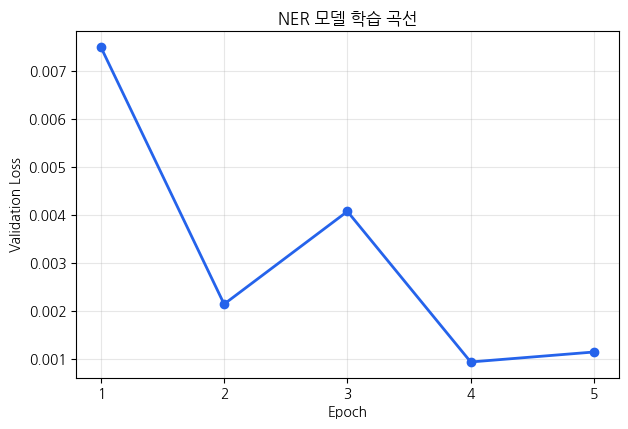

In [ ]:
log_history = trainer.state.log_history

epochs, eval_losses = [], []
for log in log_history:
    if "eval_loss" in log:
        epochs.append(log["epoch"])
        eval_losses.append(log["eval_loss"])

plt.figure(figsize=(7, 4.5))
plt.plot(epochs, eval_losses, marker='o', color='#2563eb', linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("NER 모델 학습 곡선")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.savefig("loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

그래프 2: 정규식 vs NER vs 하이브리드 비교

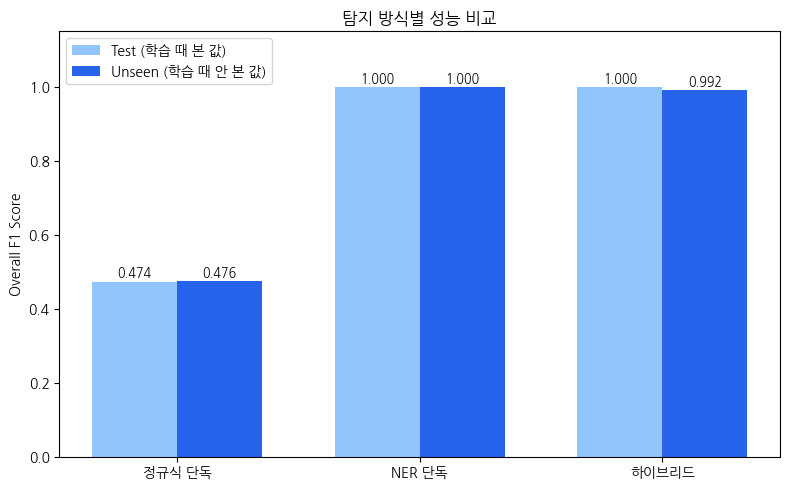

In [ ]:
methods = ["정규식 단독", "NER 단독", "하이브리드"]
test_scores = [0.474, 1.000, 1.000]
unseen_scores = [0.476, 1.000, 0.992]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, test_scores, width, label='Test (학습 때 본 값)', color='#93c5fd')
bars2 = ax.bar(x + width/2, unseen_scores, width, label='Unseen (학습 때 안 본 값)', color='#2563eb')

ax.set_ylabel('Overall F1 Score')
ax.set_title('탐지 방식별 성능 비교')
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 1.15)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("f1_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 검증용 낯선 문장 테스트 (학습에 사용 안 함, 일반화 여부 확인용)
## 추가 검증: 학습 데이터에 없는 낯선 문장으로 테스트

지금까지 F1이 계속 1.000에 가깝게 나와서, 과적합인지 진짜 일반화된 건지 확인이 필요함.
아래 25개 문장은 템플릿 구조·이름·표현을 전부 새로 만든 것으로, **학습에는 절대 사용하지 않고 이미 학습된 모델을 검증하는 용도로만** 사용.
- 문맥 신호 약한 이름, 이름/일반명사 혼동 케이스
- 도로명주소 아닌 구어체 위치 표현
- 특이한 전화번호/이메일 형식, 부정문, 외국인 이름 등 의도적으로 어려운 케이스 포함

In [ ]:
adversarial_sentences = [
    ("어제 민수랑 영화 봤어", [("민수", "PER")]),
    ("지훈이가 그러던데", [("지훈", "PER")]),
    ("장미가 정말 예쁘게 폈네요", []),
    ("이 영화 감독 이름이 봉준호였나", [("봉준호", "PER")]),
    ("최유진 오늘 회의 몇시야", [("최유진", "PER")]),
    ("연락 부탁해요 김도현", [("김도현", "PER")]),
    ("강남역 11번 출구 앞에서 만나요", []),
    ("판교역 근처로 와주세요", []),
    ("서울 종로구 쪽으로 이사가요", [("서울 종로구", "ADDR")]),
    ("전화는 (010)1234-5678 로 주세요", [("(010)1234-5678", "PHONE")]),
    ("010 1234 5678 로 문자주세요", [("010 1234 5678", "PHONE")]),
    ("010번호 끝자리가 5678이었나", []),
    ("김민수 010-1111-2222, 박지영 010-3333-4444 둘 다 저장해줘",
     [("김민수","PER"),("010-1111-2222","PHONE"),("박지영","PER"),("010-3333-4444","PHONE")]),
    ("메일주소 test.user+work@company.co.kr 로 보내주세요", [("test.user+work@company.co.kr","EMAIL")]),
    ("전화번호는 아직 몰라요", []),
    ("이름 안 가르쳐줬어요", []),
    ("John Smith가 방문할 예정입니다", [("John Smith","PER")]),
    ("주민번호: 900101/1234567 확인 부탁", [("900101/1234567","RRN")]),
]

for text, expected in adversarial_sentences:
    predict(text)
    print(f"  (기대값: {expected})")


입력: 어제 민수랑 영화 봤어
  '민수' → B-PER
  (기대값: [('민수', 'PER')])

입력: 지훈이가 그러던데
  '지훈' → B-PER
  (기대값: [('지훈', 'PER')])

입력: 장미가 정말 예쁘게 폈네요
  (기대값: [])

입력: 이 영화 감독 이름이 봉준호였나
  '봉' → B-PER
  '준호' → I-PER
  (기대값: [('봉준호', 'PER')])

입력: 최유진 오늘 회의 몇시야
  '최' → B-PER
  '유진' → I-PER
  (기대값: [('최유진', 'PER')])

입력: 연락 부탁해요 김도현
  '김도' → B-PER
  '현' → I-PER
  (기대값: [('김도현', 'PER')])

입력: 강남역 11번 출구 앞에서 만나요
  (기대값: [])

입력: 판교역 근처로 와주세요
  (기대값: [])

입력: 서울 종로구 쪽으로 이사가요
  (기대값: [('서울 종로구', 'ADDR')])

입력: 전화는 (010)1234-5678 로 주세요
  '(' → B-PHONE
  '010' → B-PHONE
  ')' → I-PHONE
  '123' → I-PHONE
  '4' → I-PHONE
  '-' → I-PHONE
  '56' → I-PHONE
  '78' → I-PHONE
  (기대값: [('(010)1234-5678', 'PHONE')])

입력: 010 1234 5678 로 문자주세요
  '010' → B-PHONE
  '123' → I-PHONE
  '4' → I-PHONE
  '56' → I-PHONE
  '78' → I-PHONE
  (기대값: [('010 1234 5678', 'PHONE')])

입력: 010번호 끝자리가 5678이었나
  '56' → B-RRN
  '78' → I-RRN
  (기대값: [])

입력: 김민수 010-1111-2222, 박지영 010-3333-4444 둘 다 저장해줘
  '김민' → B-PER
  '수' → I-PER
  '010' → B-PH

In [ ]:
adversarial_data = [
    ("어제 민수랑 영화 봤어", [("민수", "PER")]),
    ("지훈이가 그러던데", [("지훈", "PER")]),
    ("장미가 정말 예쁘게 폈네요", []),
    ("이 영화 감독 이름이 봉준호였나", [("봉준호", "PER")]),
    ("최유진 오늘 회의 몇시야", [("최유진", "PER")]),
    ("연락 부탁해요 김도현", [("김도현", "PER")]),
    ("강남역 11번 출구 앞에서 만나요", []),
    ("판교역 근처로 와주세요", []),
    ("서울 종로구 쪽으로 이사가요", [("서울 종로구", "ADDR")]),
    ("전화는 (010)1234-5678 로 주세요", [("(010)1234-5678", "PHONE")]),
    ("010 1234 5678 로 문자주세요", [("010 1234 5678", "PHONE")]),
    ("010번호 끝자리가 5678이었나", []),
    ("김민수 010-1111-2222, 박지영 010-3333-4444 둘 다 저장해줘",
     [("김민수","PER"),("010-1111-2222","PHONE"),("박지영","PER"),("010-3333-4444","PHONE")]),
    ("메일주소 test.user+work@company.co.kr 로 보내주세요", [("test.user+work@company.co.kr","EMAIL")]),
    ("전화번호는 아직 몰라요", []),
    ("이름 안 가르쳐줬어요", []),
    ("John Smith가 방문할 예정입니다", [("John Smith","PER")]),
    ("주민번호: 900101/1234567 확인 부탁", [("900101/1234567","RRN")]),
    ("선생님 성함이 어떻게 되세요? 정수빈이라고 합니다", [("정수빈","PER")]),
    ("택배기사님 성함 확인 부탁드려요 이창현", [("이창현","PER")]),
    ("회의록에 서명한 사람이 강태오인가 확인해줘", [("강태오","PER")]),
    ("우리 팀장님 성함이 조은비예요", [("조은비","PER")]),
    ("고객 응대했던 직원 이름이 배수지였어요", [("배수지","PER")]),
    ("택배 보낸사람 성함은 정해인입니다", [("정해인","PER")]),
    ("우리 반에 하늘이라는 애 있어", [("하늘","PER")]),
    ("이름값 못하네 진짜", []),
    ("성이 뭐가 중요해 능력이 중요하지", []),
    ("택배는 홍대입구역 2번출구 사물함으로 보내주세요", []),
    ("본사는 여의도에 있어요", []),
    ("집주소는 경기도 성남시 분당구입니다", [("경기도 성남시 분당구","ADDR")]),
    ("제주도 살아요 놀러오세요", []),
    ("부산 해운대 쪽으로 와주시면 됩니다", []),
    ("폰번호 이거야 010-2345-6789", [("010-2345-6789","PHONE")]),
    ("070-1234-5678로 전화주세요", [("070-1234-5678","PHONE")]),
    ("핸드폰번호 01012345678 맞죠", [("01012345678","PHONE")]),
    ("제 번호 마지막 네자리가 5678이에요", []),
    ("이메일 하나 더 있어요 abc123@daum.net", [("abc123@daum.net","EMAIL")]),
    ("메일함 확인해보니 아무것도 없던데요", []),
    ("지메일 계정 만들었어요", []),
    ("연락처는 kim.sales@company-name.co.kr입니다", [("kim.sales@company-name.co.kr","EMAIL")]),
    ("주민등록번호 앞자리만 알려주세요 950322", []),
    ("뒷자리 포함 950322-2345678 전체 번호입니다", [("950322-2345678","RRN")]),
    ("고객정보 등록합니다 이름 오민준 연락처 010-5555-1234 이메일 min@example.com",
     [("오민준","PER"),("010-5555-1234","PHONE"),("min@example.com","EMAIL")]),
    ("가격은 만원이고 010원은 아니에요", []),
    ("회의실 번호는 301호입니다", []),
    ("택배 송장번호 1234567890123 확인 부탁드려요", []),
]
print(f"총 {len(adversarial_data)}개 문장")

# (text, [(substring, label)]) → {"text":..., "entities":[{"start":.., "end":.., "label":..}]}
adversarial_jsonl = []
for text, expected in adversarial_data:
    entities = []
    for substring, label in expected:
        start = text.find(substring)
        end = start + len(substring)
        entities.append({"start": start, "end": end, "label": label})
    adversarial_jsonl.append({"text": text, "entities": entities})

with open("adversarial_test.jsonl", "w", encoding="utf-8") as f:
    for item in adversarial_jsonl:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# 실제 F1 계산 (NER 단독 기준)
adversarial_dataset = load_and_convert("adversarial_test.jsonl")
evaluate(adversarial_dataset, "Adversarial (구어체/OOD 문장)")

총 46개 문장


===== Adversarial (구어체/OOD 문장) =====
              precision    recall  f1-score   support

        ADDR      0.333     0.500     0.400         2
       EMAIL      1.000     1.000     1.000         4
         PER      0.833     0.938     0.882        16
       PHONE      0.778     0.875     0.824         8
         RRN      0.333     1.000     0.500         2

   micro avg      0.725     0.906     0.806        32
   macro avg      0.656     0.863     0.721        32
weighted avg      0.778     0.906     0.828        32

Overall F1: 0.806



np.float64(0.8055555555555555)

In [ ]:
clean_f1 = evaluate(test_dataset, "Clean (학습 때 본 이름/주소)")
unseen_f1 = evaluate(unseen_dataset, "Unseen (학습 때 안 본 이름/주소)")
adversarial_f1 = evaluate(adversarial_dataset, "Adversarial (구어체/OOD 문장)")

print(f"\n최종 확인 → Clean: {clean_f1:.3f}, Unseen: {unseen_f1:.3f}, Adversarial: {adversarial_f1:.3f}")

===== Clean (학습 때 본 이름/주소) =====
              precision    recall  f1-score   support

        ADDR      1.000     1.000     1.000        29
       EMAIL      1.000     1.000     1.000        16
         PER      1.000     1.000     1.000        95
       PHONE      1.000     1.000     1.000        37
         RRN      1.000     1.000     1.000         9

   micro avg      1.000     1.000     1.000       186
   macro avg      1.000     1.000     1.000       186
weighted avg      1.000     1.000     1.000       186

Overall F1: 1.000



===== Unseen (학습 때 안 본 이름/주소) =====
              precision    recall  f1-score   support

        ADDR      1.000     1.000     1.000        19
       EMAIL      1.000     1.000     1.000        27
         PER      1.000     1.000     1.000        68
       PHONE      1.000     1.000     1.000        29
         RRN      1.000     1.000     1.000        14

   micro avg      1.000     1.000     1.000       157
   macro avg      1.000     1.000     1.000       157
weighted avg      1.000     1.000     1.000       157

Overall F1: 1.000



===== Adversarial (구어체/OOD 문장) =====
              precision    recall  f1-score   support

        ADDR      0.333     0.500     0.400         2
       EMAIL      1.000     1.000     1.000         4
         PER      0.833     0.938     0.882        16
       PHONE      0.778     0.875     0.824         8
         RRN      0.333     1.000     0.500         2

   micro avg      0.725     0.906     0.806        32
   macro avg      0.656     0.863     0.721        32
weighted avg      0.778     0.906     0.828        32

Overall F1: 0.806


최종 확인 → Clean: 1.000, Unseen: 1.000, Adversarial: 0.806


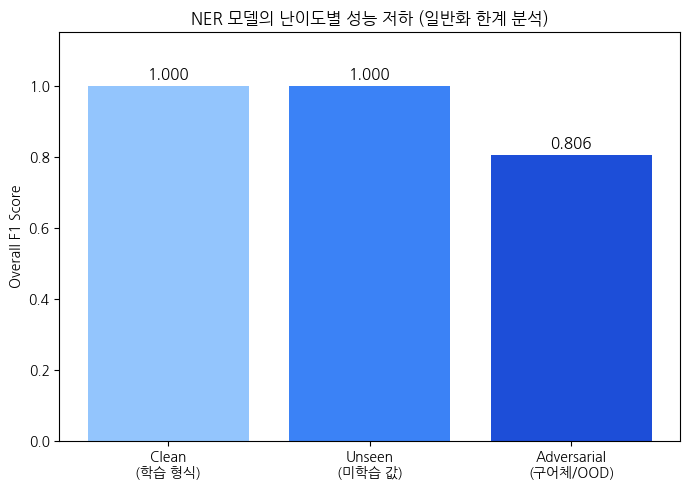

In [ ]:
tiers = ["Clean\n(학습 형식)", "Unseen\n(미학습 값)", "Adversarial\n(구어체/OOD)"]
ner_f1_by_tier = [clean_f1, unseen_f1, adversarial_f1]   # ← 하드코딩 대신 변수 직접 참조

plt.figure(figsize=(7, 5))
bars = plt.bar(tiers, ner_f1_by_tier, color=['#93c5fd', '#3b82f6', '#1d4ed8'])
plt.ylabel("Overall F1 Score")
plt.title("NER 모델의 난이도별 성능 저하 (일반화 한계 분석)")
plt.ylim(0, 1.15)
for bar, v in zip(bars, ner_f1_by_tier):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.3f}", ha='center', fontsize=11)
plt.tight_layout()
plt.savefig("f1_by_difficulty.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
addr_rrn_cases = [item for item in adversarial_data if any(label in ["ADDR", "RRN"] for _, label in item[1])]

for text, expected in addr_rrn_cases:
    predict(text)
    print(f"  (기대값: {expected})\n")


입력: 서울 종로구 쪽으로 이사가요
  (기대값: [('서울 종로구', 'ADDR')])


입력: 주민번호: 900101/1234567 확인 부탁
  '900' → B-RRN
  '10' → I-RRN
  '1' → I-RRN
  '/' → I-RRN
  '123' → I-RRN
  '45' → I-RRN
  '67' → I-RRN
  (기대값: [('900101/1234567', 'RRN')])


입력: 집주소는 경기도 성남시 분당구입니다
  '경기도' → B-ADDR
  '성남시' → I-ADDR
  '분당' → I-ADDR
  '구' → I-ADDR
  (기대값: [('경기도 성남시 분당구', 'ADDR')])


입력: 뒷자리 포함 950322-2345678 전체 번호입니다
  '950' → B-RRN
  '32' → I-RRN
  '2' → I-RRN
  '-' → I-RRN
  '234' → I-RRN
  '56' → I-RRN
  '78' → I-RRN
  (기대값: [('950322-2345678', 'RRN')])



In [ ]:
for text, expected in adversarial_data:
    expected_labels = set(l for _, l in expected)
    if "ADDR" in expected_labels or "RRN" in expected_labels:
        continue  # 방금 이미 확인한 케이스는 건너뜀

    encoding = tokenizer(text, return_offsets_mapping=True, return_tensors="pt")
    offsets = encoding.pop("offset_mapping")[0]
    encoding = {k: v.to(model.device) for k, v in encoding.items()}
    with torch.no_grad():
        outputs = model(**encoding)
    preds = outputs.logits.argmax(dim=2)[0]

    found_wrong = False
    for idx, (s, e) in enumerate(offsets):
        if s == e:
            continue
        label = id2label[preds[idx].item()]
        if "ADDR" in label or "RRN" in label:
            found_wrong = True

    if found_wrong:
        print(f"\n[오탐 의심] {text}")
        predict(text)
        print(f"  (원래 기대값: {expected} ← 여기 ADDR/RRN 없어야 정상)")


[오탐 의심] 010번호 끝자리가 5678이었나

입력: 010번호 끝자리가 5678이었나
  '56' → B-RRN
  '78' → I-RRN
  (원래 기대값: [] ← 여기 ADDR/RRN 없어야 정상)

[오탐 의심] 택배는 홍대입구역 2번출구 사물함으로 보내주세요

입력: 택배는 홍대입구역 2번출구 사물함으로 보내주세요
  '홍대' → B-ADDR
  '입' → I-ADDR
  '구역' → I-ADDR
  '2' → I-ADDR
  '번' → I-ADDR
  '구' → I-ADDR
  (원래 기대값: [] ← 여기 ADDR/RRN 없어야 정상)

[오탐 의심] 제 번호 마지막 네자리가 5678이에요

입력: 제 번호 마지막 네자리가 5678이에요
  '56' → B-RRN
  '78' → I-RRN
  (원래 기대값: [] ← 여기 ADDR/RRN 없어야 정상)

[오탐 의심] 주민등록번호 앞자리만 알려주세요 950322

입력: 주민등록번호 앞자리만 알려주세요 950322
  '950' → B-RRN
  '32' → I-RRN
  '2' → I-RRN
  (원래 기대값: [] ← 여기 ADDR/RRN 없어야 정상)

[오탐 의심] 택배 송장번호 1234567890123 확인 부탁드려요

입력: 택배 송장번호 1234567890123 확인 부탁드려요
  '123' → B-RRN
  '45' → I-RRN
  '67' → I-RRN
  '89' → I-RRN
  '0' → I-RRN
  '12' → I-RRN
  '3' → I-RRN
  (원래 기대값: [] ← 여기 ADDR/RRN 없어야 정상)


그래프

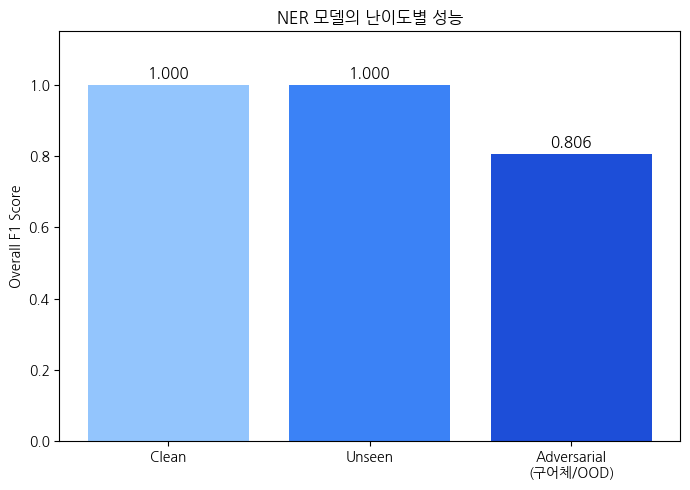

In [ ]:
tiers = ["Clean", "Unseen", "Adversarial\n(구어체/OOD)"]
# evaluate()에서 return한 score로 각 f1_score를 리스트로 묶음
scores = [clean_f1, unseen_f1, adversarial_f1]

plt.figure(figsize=(7, 5))
colors = ['#93c5fd', '#3b82f6', '#1d4ed8']
bars = plt.bar(tiers, scores, color=colors)
plt.ylabel("Overall F1 Score")
plt.title("NER 모델의 난이도별 성능")
plt.ylim(0, 1.15)
for bar, v in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.3f}", ha='center', fontsize=11)
plt.tight_layout()
plt.savefig("f1_final_summary.png", dpi=150, bbox_inches="tight")
plt.show()

모델 저장

In [ ]:
model.save_pretrained("./ner_model_final")
tokenizer.save_pretrained("./ner_model_final")

# 라벨 매핑 정보도 같이 저장 (나중에 EC2에서 로드할 때 필요)
import json
with open("./ner_model_final/label_map.json", "w", encoding="utf-8") as f:
    json.dump({"id2label": id2label, "label2id": label2id}, f, ensure_ascii=False)

print("저장 완료")
!ls -la ./ner_model_final

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

저장 완료
total 430608
drwxr-xr-x 2 root root      4096 Sep  6 14:54 .
drwxr-xr-x 1 root root      4096 Sep  6 14:54 ..
-rw-r--r-- 1 root root      1116 Sep  6 14:54 config.json
-rw-r--r-- 1 root root       328 Sep  6 14:54 label_map.json
-rw------- 1 root root 440164196 Sep  6 14:54 model.safetensors
-rw-r--r-- 1 root root       404 Sep  6 14:54 tokenizer_config.json
-rw-r--r-- 1 root root    751999 Sep  6 14:54 tokenizer.json


## 모델 저장 완료 — 최종 파일 목록

| 파일명 | 설명 |
|---|---|
| `config.json` | 모델 구조 정보 |
| `model.safetensors` | 가중치 (440MB) |
| `tokenizer_config.json` | 토크나이저 설정 |
| `tokenizer.json` | 어휘사전+특수토큰 통합 파일 (최신 버전 방식, `vocab.txt`+`special_tokens_map.json` 대체) |
| `label_map.json` | 라벨 매핑 정보 (안전장치로 추가 저장) |

**총 용량**: 약 440MB (model.safetensors가 대부분 차지)

다음 단계: Google Drive 마운트 → 폴더 압축(zip) → Drive에 복사 → EC2에서 다운로드


저장한 모델 GOOGLE DRIVE로 옮기기

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

# 폴더 전체를 zip으로 압축
shutil.make_archive("ner_model_final", 'zip', "./ner_model_final")

# 압축된 파일을 Drive로 복사
!cp ner_model_final.zip /content/drive/MyDrive/

print("Drive 저장 완료")
!ls -la /content/drive/MyDrive/ner_model_final.zip

Drive 저장 완료
-rw------- 1 root root 408860002 Sep  6 15:10 /content/drive/MyDrive/ner_model_final.zip
